In [22]:
import pandas as pd

# Load the original dataset without modifying it
df_original = pd.read_csv("../data/H2.csv")

# Create a separate version with exact duplicate rows removed
df_non_duplicated = df_original.drop_duplicates().copy()

# Compare their sizes
print("Original dataset shape:", df_original.shape)
print("Deduplicated dataset shape:", df_non_duplicated.shape)
print("Duplicate occurrences removed:",
      len(df_original) - len(df_non_duplicated))


Original dataset shape: (79330, 31)
Deduplicated dataset shape: (53428, 31)
Duplicate occurrences removed: 25902


In [23]:
from sklearn.impute import SimpleImputer # fills missing values using a chosen rule.
from sklearn.compose import ColumnTransformer # applies different rules to numeric and categorical columns.
from sklearn.pipeline import Pipeline # connects preprocessing and model training into one workflow.
from sklearn.preprocessing import OneHotEncoder # converts categories into numeric features.
from sklearn.preprocessing import StandardScaler # puts numeric features on comparable scales when needed
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

In [24]:
# Columns that would cause information leakage in classification model
leakage_columns = [
    "ADR"
]

dropped_columns = [
    "Babies",
    "Company",
    "DaysInWaitingList",
    "ArrivalDateDayOfMonth",
    "ArrivalDateYear",
    "PreviousBookingsNotCanceled",
    "ReservationStatus",
    "ReservationStatusDate",
    "ReservedRoomType",
    "IsCanceled"
]

# Remove rows with no adults and no children
rows_before = len(df_original)

df_original = df_original[
    (df_original["Adults"] + df_original["Children"].fillna(0)) > 0
].copy()

# Reset index
df_original.reset_index(drop=True, inplace=True)


# Separate features (X) and target (y)
X_original = df_original.drop(
    columns= dropped_columns + leakage_columns
)
y_original = df_original["ADR"]

X_non_duplicated = df_non_duplicated.drop(
    columns= dropped_columns + leakage_columns
)
y_non_duplicated = df_non_duplicated["ADR"]

# Display results
print("Rows removed:", rows_before - len(X_original))
print("Remaining rows:", len(X_original))
print("Remaining columns:", X_original.shape[1])
# Check the resulting dimensions
print("Original features:", X_original.shape)
print("Original target:", y_original.shape)

print("Deduplicated features:", X_non_duplicated.shape)
print("Deduplicated target:", y_non_duplicated.shape)

Rows removed: 167
Remaining rows: 79163
Remaining columns: 20
Original features: (79163, 20)
Original target: (79163,)
Deduplicated features: (53428, 20)
Deduplicated target: (53428,)


In [25]:
from sklearn.model_selection import GroupShuffleSplit

# Identify identical feature-and-target records
groups_original = pd.util.hash_pandas_object(
    pd.concat([X_original, y_original.rename("ADR")], axis=1),
    index=False
).to_numpy()

groups_non_duplicated = pd.util.hash_pandas_object(
    pd.concat([
        X_non_duplicated,
        y_non_duplicated.rename("ADR")
    ], axis=1),
    index=False
).to_numpy()


# Split the original dataset
splitter_original = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=233
)

train_idx_original, test_idx_original = next(
    splitter_original.split(
        X_original, y_original, groups_original
    )
)

X_train_original = X_original.iloc[train_idx_original]
X_test_original = X_original.iloc[test_idx_original]
y_train_original = y_original.iloc[train_idx_original]
y_test_original = y_original.iloc[test_idx_original]


# Split the dataset without duplicates
splitter_non_duplicated = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=233
)

train_idx_non_duplicated, test_idx_non_duplicated = next(
    splitter_non_duplicated.split(
        X_non_duplicated,
        y_non_duplicated,
        groups_non_duplicated
    )
)

X_train_non_duplicated = X_non_duplicated.iloc[
    train_idx_non_duplicated
]
X_test_non_duplicated = X_non_duplicated.iloc[
    test_idx_non_duplicated
]
y_train_non_duplicated = y_non_duplicated.iloc[
    train_idx_non_duplicated
]
y_test_non_duplicated = y_non_duplicated.iloc[
    test_idx_non_duplicated
]


# Display split sizes
print("ORIGINAL DATASET")
print("Training rows:", len(X_train_original))
print("Testing rows:", len(X_test_original))

print("\nNON-DUPLICATED DATASET")
print("Training rows:", len(X_train_non_duplicated))
print("Testing rows:", len(X_test_non_duplicated))


# Check for group overlap
print(
    "\nOriginal groups overlap:",
    bool(
        set(groups_original[train_idx_original])
        & set(groups_original[test_idx_original])
    )
)

print(
    "Non-duplicated groups overlap:",
    bool(
        set(groups_non_duplicated[train_idx_non_duplicated])
        & set(groups_non_duplicated[test_idx_non_duplicated])
    )
)


ORIGINAL DATASET
Training rows: 63533
Testing rows: 15630

NON-DUPLICATED DATASET
Training rows: 42739
Testing rows: 10689

Original groups overlap: False
Non-duplicated groups overlap: False


In [26]:
# Identify numeric and categorical columns from the training data
numeric_features = X_train_original.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train_original.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Number of numeric features:", len(numeric_features))
print("Numeric features:", numeric_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:", categorical_features)

Number of numeric features: 11
Numeric features: ['LeadTime', 'ArrivalDateWeekNumber', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'IsRepeatedGuest', 'PreviousCancellations', 'BookingChanges', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests']

Number of categorical features: 9
Categorical features: ['ArrivalDateMonth', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'AssignedRoomType', 'DepositType', 'Agent', 'CustomerType']


In [27]:
# Low-cardinality categorical features
# These will be one-hot encoded directly.
# ArrivalDateMonth here is with low caridality even tho it has more than 10 crdial values but because it is managable to be 12 and they are important so it is manegable
low_cardinality_features = [
    "AssignedRoomType",
    "MarketSegment",
    "DistributionChannel",
    "Meal",
    "CustomerType",
    "DepositType",
    "ArrivalDateMonth"
]

# High-cardinality categorical features
# Rare categories will be grouped into "Other".

high_cardinality_features = [
    "Agent",
    "Country"
]

print("Low-cardinality features:", low_cardinality_features)
print("High-cardinality features:", high_cardinality_features)

Low-cardinality features: ['AssignedRoomType', 'MarketSegment', 'DistributionChannel', 'Meal', 'CustomerType', 'DepositType', 'ArrivalDateMonth']
High-cardinality features: ['Agent', 'Country']


In [28]:
from sklearn.base import BaseEstimator, TransformerMixin

class RareCategoryGrouper(BaseEstimator, TransformerMixin):
    def __init__(self, min_frequency=0.01): ## if this value is less than 1% of the vlues in the data then it is considered rare and put with "other" category
        self.min_frequency = min_frequency

    def fit(self, X, y=None):
        self.frequent_categories_ = {}

        X = X.copy()

        for column in X.columns:
            # Convert non-missing values to strings
            # while preserving missing values
            X[column] = X[column].astype(object).where(
                X[column].isna(),
                X[column].astype(str)
            )

            # Calculate the proportion of each category
            frequencies = X[column].value_counts(
                normalize=True,
                dropna=True
            )

            # Keep categories appearing in at least 1% of training rows
            self.frequent_categories_[column] = set(
                frequencies[
                    frequencies >= self.min_frequency
                ].index
            )

        return self

    def transform(self, X):
        X = X.copy()

        for column in X.columns:
            # Apply the same conversion used during fitting
            X[column] = X[column].astype(object).where(
                X[column].isna(),
                X[column].astype(str)
            )

            frequent = self.frequent_categories_[column]

            # Replace rare categories with "Other"
            # Keep missing values for the imputer
            X[column] = X[column].where(
                X[column].isna() | X[column].isin(frequent),
                "Other"
            )

        return X

In [29]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Numeric features:
# Fill missing values with the median, then scale the values.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 2. Low-cardinality categorical features:
# Fill missing values with the most frequent category,
# then one-hot encode the categories.
low_cardinality_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 3. High-cardinality categorical features:
# Group rare categories, fill missing values, then one-hot encode.
high_cardinality_transformer = Pipeline(steps=[
    ("rare_grouper", RareCategoryGrouper(min_frequency=0.01)),
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the three preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("low_cardinality", low_cardinality_transformer,
     low_cardinality_features),
    ("high_cardinality", high_cardinality_transformer,
     high_cardinality_features)
])

print("Cardinality-aware preprocessing pipeline created.")

Cardinality-aware preprocessing pipeline created.


In [30]:
# Learn preprocessing rules from the original training data
X_train_original_transformed = preprocessor.fit_transform(
    X_train_original
)

# Apply those same rules to the original test data
X_test_original_transformed = preprocessor.transform(
    X_test_original
)

print("Original dataset preprocessing complete.")
print("Transformed training shape:", X_train_original_transformed.shape)
print("Transformed testing shape:", X_test_original_transformed.shape)

Original dataset preprocessing complete.
Transformed training shape: (63533, 84)
Transformed testing shape: (15630, 84)


Total original regression features after preprocessing: 84
Number of components needed for 95% explained variance: 33


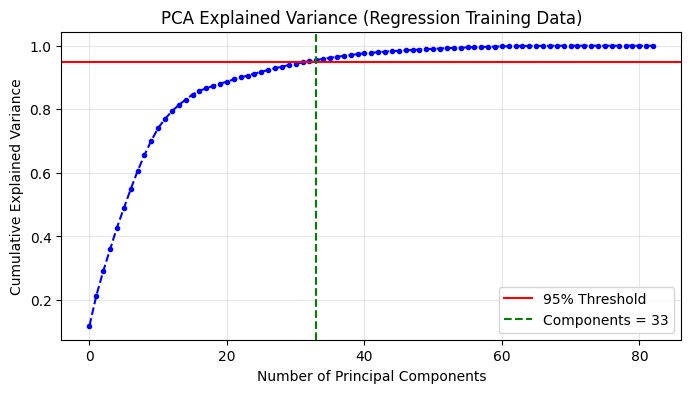


Regression pipelines ready:
 - reg_pipeline_original
 - reg_pipeline_pca


In [31]:
# Fit PCA on regression training data
pca_full_reg = PCA(random_state=233)
pca_full_reg.fit(X_train_original_transformed)

# Calculate cumulative explained variance
cum_variance_reg = np.cumsum(pca_full_reg.explained_variance_ratio_)
n_components_95_reg = np.argmax(cum_variance_reg >= 0.95) + 1

print(f"Total original regression features after preprocessing: {X_train_original_transformed.shape[1]}")
print(f"Number of components needed for 95% explained variance: {n_components_95_reg}")

# Plot explained variance curve
plt.figure(figsize=(8, 4))
plt.plot(cum_variance_reg, marker='.', linestyle='--', color='b')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Threshold')
plt.axvline(x=n_components_95_reg, color='g', linestyle='--', label=f'Components = {n_components_95_reg}')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Explained Variance (Regression Training Data)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

# Define the Complete Regression Pipelines (Original vs PCA)
reg_pipeline_original = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

reg_pipeline_pca = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("pca", PCA(n_components=n_components_95_reg, random_state=233)),
    ("regressor", LinearRegression())
])

print("\nRegression pipelines ready:")
print(" - reg_pipeline_original")
print(" - reg_pipeline_pca")

In [32]:
# Original Regression Pipeline
reg_pipeline_original.fit(X_train_original, y_train_original)
y_pred_reg_orig = reg_pipeline_original.predict(X_test_original)

rmse_orig = np.sqrt(mean_squared_error(y_test_original, y_pred_reg_orig))
r2_orig = r2_score(y_test_original, y_pred_reg_orig)

print("=== Original Regression Model ===")
print(f"RMSE:     {rmse_orig:.4f}")
print(f"R2 Score: {r2_orig:.4f}\n")

# --- 2. PCA Regression Pipeline ---
reg_pipeline_pca.fit(X_train_original, y_train_original)
y_pred_reg_pca = reg_pipeline_pca.predict(X_test_original)

rmse_pca = np.sqrt(mean_squared_error(y_test_original, y_pred_reg_pca))
r2_pca = r2_score(y_test_original, y_pred_reg_pca)

print("=== PCA Regression Model ===")
print(f"RMSE:     {rmse_pca:.4f}")
print(f"R2 Score: {r2_pca:.4f}")

=== Original Regression Model ===
RMSE:     24.1885
R2 Score: 0.6210

=== PCA Regression Model ===
RMSE:     27.2934
R2 Score: 0.5174
